**1. Introduction**
This project investigates how demographic, educational and employment characteristics can be used to predict whether an individual's annual income exceeds $50,000. This analysis focuses on the effect of regularization and model complexity on predictive performance, as well as feature importance.

In [2]:
# importing necessary libraries for EDA
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

**2. Data loading and Preprocessing**
The Adult dataset was loaded using Pandas and inspected to examine its structure, missing values, data types and duplicates.

In [5]:
columns = ['age','workclass','fnlwgt','education','education-num','marital-status','occupation','relationship','race','sex','capital-gain','capital-loss','hours-per-week','native-country','income']
df = pd.read_csv('adult.data',header=None, names=columns)
df.info() # datatypes
print(df.shape) # checking number of rows and columns

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             32561 non-null  int64 
 1   workclass       32561 non-null  object
 2   fnlwgt          32561 non-null  int64 
 3   education       32561 non-null  object
 4   education-num   32561 non-null  int64 
 5   marital-status  32561 non-null  object
 6   occupation      32561 non-null  object
 7   relationship    32561 non-null  object
 8   race            32561 non-null  object
 9   sex             32561 non-null  object
 10  capital-gain    32561 non-null  int64 
 11  capital-loss    32561 non-null  int64 
 12  hours-per-week  32561 non-null  int64 
 13  native-country  32561 non-null  object
 14  income          32561 non-null  object
dtypes: int64(6), object(9)
memory usage: 3.7+ MB
(32561, 15)


In [6]:
df.head()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [7]:
# checking for null values
print(df.isna().sum())

age               0
workclass         0
fnlwgt            0
education         0
education-num     0
marital-status    0
occupation        0
relationship      0
race              0
sex               0
capital-gain      0
capital-loss      0
hours-per-week    0
native-country    0
income            0
dtype: int64


In [8]:
# checking duplicates
print(df.duplicated().sum())

duplicated_rows = df[df.duplicated()]
# dropping duplicate rows 
df_cleaned = df.drop_duplicates()

print(df_cleaned.duplicated().sum())

24
0


**3. Exploratory Data Analysis (EDA)**
Exploratory Data Analysis was conducted to examine the distribution of income and explore relationships between income and selected input features, such as, education, age and hours worked. Different types of visualisations were used to identify patterns and correlation among numerical variables.

In [17]:
# summary statistics for numerical variables
summary = pd.DataFrame({
    "Mean":round(df_cleaned.mean(numeric_only=True),2),
    "Median": round(df_cleaned.median(numeric_only=True),2),
    "Standard deviation": round(df_cleaned.std(numeric_only=True),2),
    "Maximum": round(df_cleaned.max(numeric_only=True),2),
    "Minimum": round(df_cleaned.min(numeric_only=True),2)
}).sort_values(by='Mean', ascending=False)

summary

,Mean,Median,Standard deviation,Maximum,Minimum
fnlwgt,189780.85,178356.0,105556.47,1484705,12285
capital-gain,1078.44,0.0,7387.96,99999,0
capital-loss,87.37,0.0,403.10,4356,0
hours-per-week,40.44,40.0,12.35,99,1
age,38.59,37.0,13.64,90,17
education-num,10.08,10.0,2.57,16,1


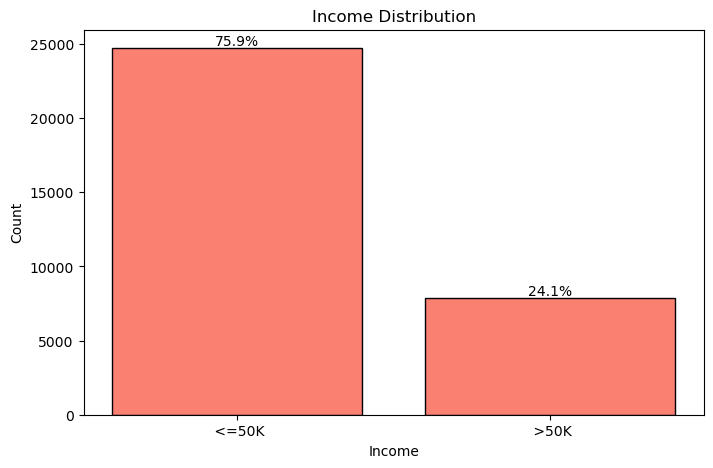

In [22]:
# examining class imbalance
counts = df['income'].value_counts()
plt.figure(figsize=(8,5))
bars = plt.bar(counts.index,counts.values)

plt.bar(counts.index, counts.values, color='salmon',edgecolor='black')
plt.title("Income Distribution")
plt.xlabel("Income")
plt.ylabel("Count")

for bar, count in zip(bars, counts.values):
    percentage = count/len(df)*100
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height(),
        f"{percentage:.1f}%",
        ha='center',
        va='bottom')

plt.show()


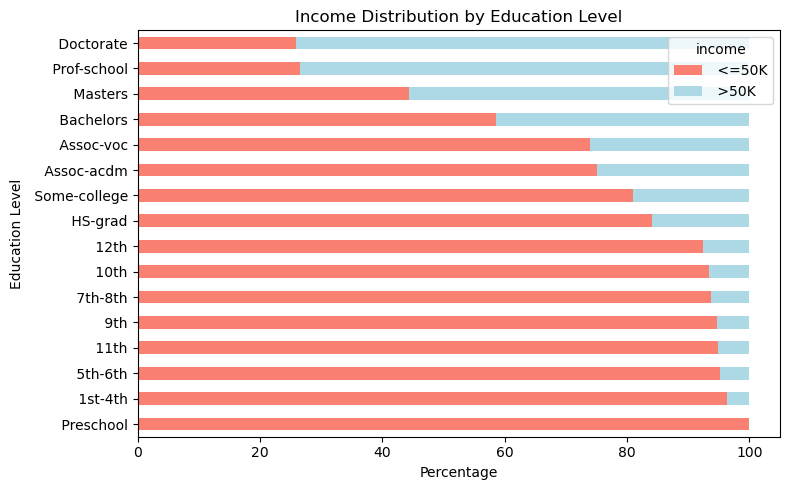

In [21]:
# Visualising income distribution across different education levels
income_table = pd.crosstab(
    df_cleaned['education'],
    df_cleaned['income'],
    normalize = 'index'
)*100

income_table = income_table.sort_values(" >50K")

income_table.plot(
    kind = 'barh',
    color = ['salmon','lightblue'],
    stacked = True,
    figsize=(8,5))
plt.xlabel("Percentage")
plt.ylabel("Education Level")
plt.title("Income Distribution by Education Level")
plt.tight_layout()
plt.show()

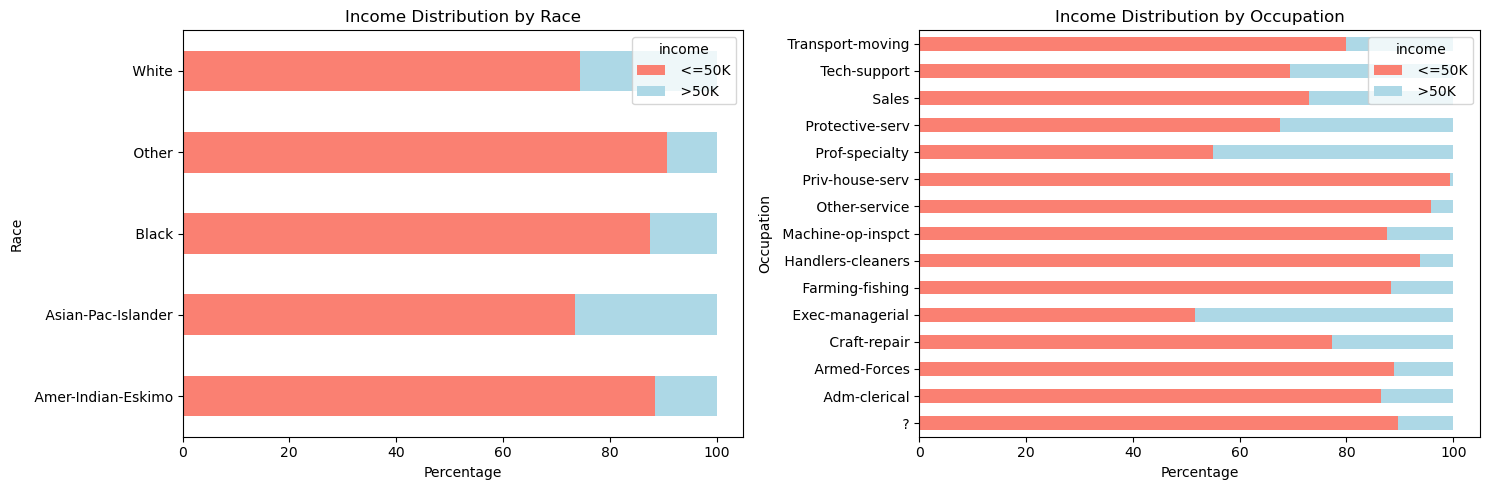

In [15]:
fig, axes = plt.subplots(1,2,figsize=(15,5))

# visualising income distribution across different races and occupations
race_income_table = pd.crosstab(
    df_cleaned['race'],
    df_cleaned['income'],
    normalize = 'index'
)*100
race_income_table.plot(
    kind = 'barh',
    color = ['salmon','lightblue'],
    stacked = True,
    ax = axes[0]
)
axes[0].set_title("Income Distribution by Race")
axes[0].set_xlabel("Percentage")
axes[0].set_ylabel("Race")

occupation_income_table = pd.crosstab(
    df_cleaned['occupation'],
    df_cleaned['income'],
    normalize = 'index'
)*100
occupation_income_table.plot(
    kind = 'barh',
    color = ['salmon','lightblue'],
    stacked = True,
    ax=axes[1]
)
axes[1].set_title("Income Distribution by Occupation")
axes[1].set_xlabel("Percentage")
axes[1].set_ylabel("Occupation")

plt.tight_layout()
plt.show()

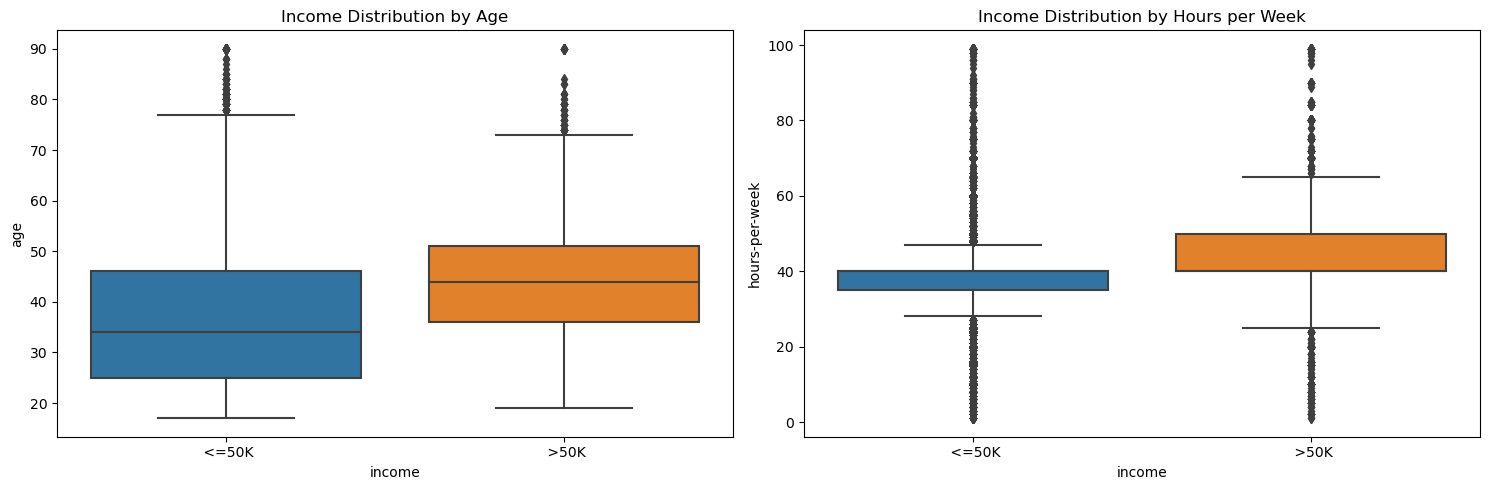

In [24]:
# visualising income distribution across different ages and hour worked
fig, axes = plt.subplots(1,2,figsize=(15,5))
sns.boxplot(data=df_cleaned, x='income',y='age',ax=axes[0])
axes[0].set_title("Income Distribution by Age")

sns.boxplot(data=df_cleaned,x='income',y='hours-per-week',ax=axes[1])
axes[1].set_title("Income Distribution by Hours per Week")

plt.tight_layout()
plt.show()

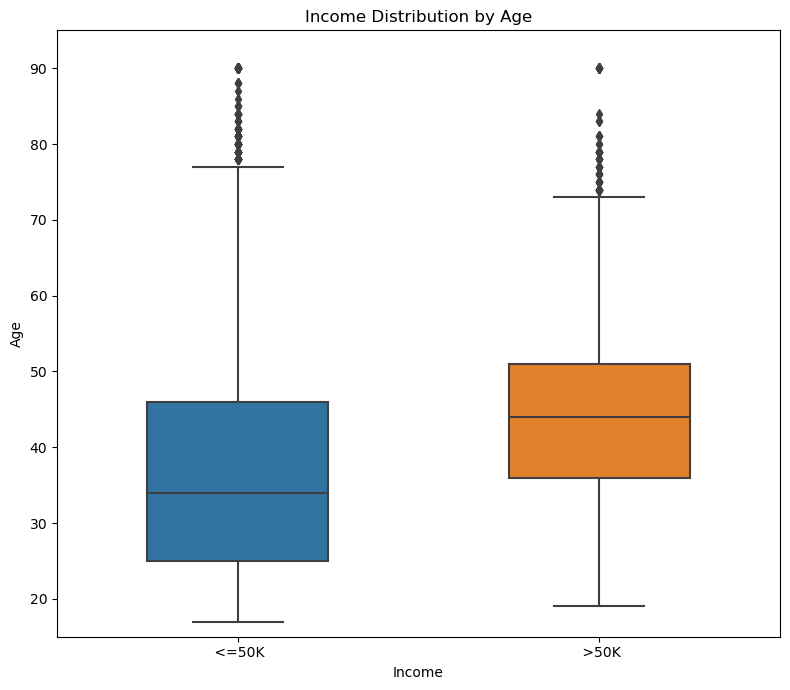

In [ ]:
# visualising income distribution across different ages 
plt.figure(figsize=(8,7))
sns.boxplot(
    data = df_cleaned,
    x = 'income',
    y = 'age', 
    width = 0.5,
)
plt.xlabel("Income")
plt.ylabel("Age")
plt.title("Income Distribution by Age")

plt.ylim(15,95)
plt.tight_layout()
plt.show()


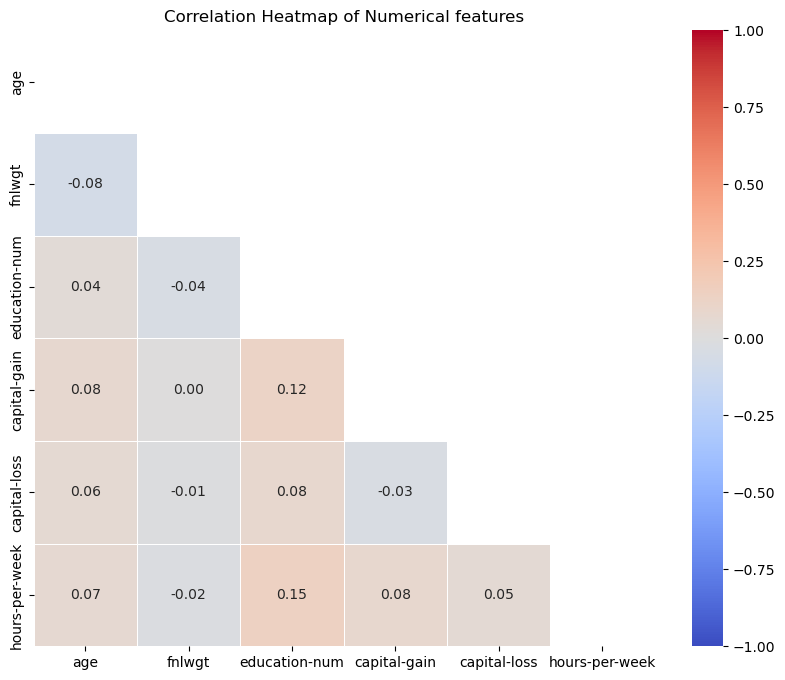

In [26]:
#correlation heatmap between numerical features
corr_matrix = df_cleaned.corr(numeric_only=True) # computing the correlation matrix for numerical features
mask = np.triu(np.ones_like(corr_matrix,dtype = bool)) # generates a mask for the upper triange

plt.figure(figsize=(10,8))
sns.heatmap(
    corr_matrix, 
    cmap = 'coolwarm',
    annot = True,
    fmt = '.2f',
    vmin =-1, vmax=1,
    mask = mask, # hides redundant upper triangle
    linewidths=0.5
)
plt.title("Correlation Heatmap of Numerical features")
plt.show()

The target variable was separated from the predictor variables. Numerical and categorical variables were identified and appropriate preprocessing was applied. Categorical variables were converted using One-Hot encoding while numerical variables were scaled.

In [27]:
# separate features and target variable
X = df_cleaned.drop('income',axis=1)
y = df_cleaned['income']

# separating categorical and numerical features
categorical_features = X.select_dtypes(include=['object']).columns
numerical_features = X.select_dtypes(include=['number']).columns

# One-hot encoding for categorical features
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)
print(numerical_features)
print(categorical_features)

Index(['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss',
       'hours-per-week'],
      dtype='object')
Index(['workclass', 'education', 'marital-status', 'occupation',
       'relationship', 'race', 'sex', 'native-country'],
      dtype='object')


**4. Model Development**

Two classification models were implemented, logistic regression and random forest. 

In [28]:
# splitting the dataset into training and testing sets
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y,random_state=42)

# setting up logistic regression and random forest pipelines
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

# no regularization for logistic regression
logistic_pipeline = Pipeline(steps=[
    ('preprocessor',preprocessor),
    ('logistic',LogisticRegression(penalty=None,max_iter=1000, random_state=42))
])
rf_pipeline = Pipeline(steps=[
    ('preprocessor',preprocessor),
    ('rf',RandomForestClassifier(n_estimators=10, max_depth=5, random_state =42))
])
# cross-validation on training data 
from sklearn.model_selection import cross_validate, StratifiedKFold
from sklearn.metrics import make_scorer, accuracy_score, precision_score, recall_score, f1_score

cv = StratifiedKFold(
    n_splits = 5,
    shuffle = True, 
    random_state = 42
)
pos = ' >50K'
scoring = {
    'accuracy': 'accuracy',
    'precision': make_scorer(precision_score, pos_label=pos),
    'recall': make_scorer(recall_score,pos_label=pos),
    'f1': make_scorer(f1_score,pos_label=pos),
    'roc_auc': 'roc_auc'
}
# cross validation on training data 
logistic_cv = cross_validate(
    logistic_pipeline, 
    X_train, 
    y_train,
    cv = cv,
    scoring = scoring, 
    n_jobs = -1
)
rf_cv = cross_validate(
    rf_pipeline, 
    X_train, 
    y_train, 
    cv = cv,
    scoring = scoring,
    n_jobs = -1,
    return_train_score = True
)
# summarising cross validation results
def summarise_cv(results):
    return pd.DataFrame({
        m:[
            results[f'test_{m}'].mean(),
            results[f'test_{m}'].std()
        ]
        for m in scoring
    },index=['Mean','Std']
    )
print("Logistic Regression Cross Validation Results:")
display(summarise_cv(logistic_cv))
print("Random Forest Cross Validation Results:")
display(summarise_cv(rf_cv))


Logistic Regression Cross Validation Results:


,accuracy,precision,recall,f1,roc_auc
Mean,0.850206,0.732658,0.595598,0.657034,0.905059
Std,0.001202,0.003152,0.006155,0.003832,0.002196


Random Forest Cross Validation Results:


,accuracy,precision,recall,f1,roc_auc
Mean,0.827538,0.814767,0.367575,0.505760,0.891612
Std,0.008246,0.021129,0.034770,0.035961,0.004279


In [29]:
# fitting the models
logistic_pipeline.fit(X_train, y_train)
rf_pipeline.fit(X_train, y_train)

# make predictions on the test set
y_pred_logistic = logistic_pipeline.predict(X_test)
y_pred_rf = rf_pipeline.predict(X_test)


In [30]:
# evaluating the models
from sklearn.metrics import classification_report, confusion_matrix, f1_score, roc_auc_score, roc_curve, auc

print("Logistic Regression Classification Report:")
print(classification_report(y_test,y_pred_logistic,target_names=[' <=50K',' >50K']))
print("Logistic Regression Confusion Matrix:\n", confusion_matrix(y_test, y_pred_logistic))

print("Random Forest Classification Report:")
print(classification_report(y_test,y_pred_rf,target_names=[' <=50K',' >50K']))
print("Random Forest Confusion Matrix:\n", confusion_matrix(y_test, y_pred_rf))

Logistic Regression Classification Report:
              precision    recall  f1-score   support

       <=50K       0.89      0.93      0.91      4940
        >50K       0.74      0.63      0.68      1568

    accuracy                           0.86      6508
   macro avg       0.81      0.78      0.79      6508
weighted avg       0.85      0.86      0.85      6508

Logistic Regression Confusion Matrix:
 [[4597  343]
 [ 583  985]]
Random Forest Classification Report:
              precision    recall  f1-score   support

       <=50K       0.83      0.98      0.90      4940
        >50K       0.86      0.35      0.50      1568

    accuracy                           0.83      6508
   macro avg       0.85      0.67      0.70      6508
weighted avg       0.84      0.83      0.80      6508

Random Forest Confusion Matrix:
 [[4853   87]
 [1013  555]]


**5. Regularisation: L1 and L2**

 L1 (Lasso) and L2 (Ridge) regularisation were compared, with GridSearchCV used to identify the optimal regularisation parameter (C) based on cross-validation F1-score.

In [31]:
# L1 regularisation
logistic_l1 = Pipeline(steps=[
    ('preprocessor',preprocessor),
    ('l1', LogisticRegression(penalty='l1',max_iter=100,random_state=42,solver='liblinear'))
])
#L2 regularisation
logistic_l2 = Pipeline(steps=[
    ('preprocessor',preprocessor),
    ('l2', LogisticRegression(penalty='l2',max_iter=100,random_state=42,solver='liblinear'))
])

In [32]:
# finding optimal c value
C_values = np.logspace(-3,2,6) # defining the values of c

from sklearn.model_selection import GridSearchCV
param_grid = {
    'l1__C': C_values
    }
# defining a custom f1 scorer
f1_scorer = make_scorer(
    f1_score, 
    pos_label = ' >50K'
)
l1_optimal = GridSearchCV(
    logistic_l1,
    param_grid,
    cv = cv, 
    scoring =f1_scorer,
    n_jobs =-1
)

l1_optimal.fit(X_train, y_train)
print("Best l1 C: ", l1_optimal.best_params_)
print("Best CV F1: ", l1_optimal.best_score_)



Best l1 C:  {'l1__C': 10.0}
Best CV F1:  0.6570937316730843


In [33]:
param_grid = {
    'l2__C': C_values
}
l2_optimal = GridSearchCV(
    logistic_l2,
    param_grid, 
    scoring = f1_scorer,
    cv= cv,
    n_jobs=-1
)
l2_optimal.fit(X_train, y_train)
print("Best l1 C: ", l2_optimal.best_params_)
print("Best CV F1: ", l2_optimal.best_score_ )

Best l1 C:  {'l2__C': 10.0}
Best CV F1:  0.6572156605865767


In [34]:
# optimal C values
best_l1 = l1_optimal.best_estimator_
best_l2 = l2_optimal.best_estimator_

# fitting the l1 and l2 regularisation models
best_l1.fit(X_train, y_train)
best_l2.fit(X_train, y_train)


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  Index(['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss',
       'hours-per-week'],
      dtype='object')),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  Index(['workclass', 'education', 'marital-status', 'occupation',
       'relationship', 'race', 'sex', 'native-country'],
      dtype='object'))])),
                ('l2',
                 LogisticRegression(C=10.0, random_state=42,
                                    solver='liblinear'))])

In [35]:
y_pred_l1 = best_l1.predict(X_test)
y_pred_l2 = best_l2.predict(X_test)

In [36]:
# evaluating l1 and l2 regularisation models
print("L1 Classification Report:")
print(classification_report(y_test,y_pred_l1,target_names=[' <=50K',' >50K']))
print("L1 Confusion Matrix:\n", confusion_matrix(y_test, y_pred_l1))

print("L2 Classification Report:")
print(classification_report(y_test,y_pred_l2,target_names=[' <=50K',' >50K']))
print("L2 Confusion Matrix:\n", confusion_matrix(y_test, y_pred_l2))

L1 Classification Report:
              precision    recall  f1-score   support

       <=50K       0.89      0.93      0.91      4940
        >50K       0.74      0.63      0.68      1568

    accuracy                           0.86      6508
   macro avg       0.81      0.78      0.79      6508
weighted avg       0.85      0.86      0.85      6508

L1 Confusion Matrix:
 [[4597  343]
 [ 584  984]]
L2 Classification Report:
              precision    recall  f1-score   support

       <=50K       0.89      0.93      0.91      4940
        >50K       0.74      0.63      0.68      1568

    accuracy                           0.86      6508
   macro avg       0.81      0.78      0.79      6508
weighted avg       0.85      0.86      0.85      6508

L2 Confusion Matrix:
 [[4597  343]
 [ 583  985]]


**6. Random Forest Model Complexity**

The effect of model complexity on random forest performance was investigated by varying the maximum tree depth (`max_depth`). Training and cross-validation F1-scores were compared to examine how tree depth influences model performance and generalisation. 

In [37]:
# implementing a random forest classifier with 100 trees and max depth 15
param_grid_rf = {
    'rf__max_depth':[2,3,5,10,15,20,50,100,None]
}
rf_grid = GridSearchCV(
    rf_pipeline,
    param_grid_rf, 
    cv = cv,
    scoring = f1_scorer,
    n_jobs=-1, 
    return_train_score=True
)
rf_grid.fit(X_train,y_train)

print("Best parameters : ", rf_grid.best_params_)
print("Best CV F1: ", rf_grid.best_score_ )


Best parameters :  {'rf__max_depth': 20}
Best CV F1:  0.659603296470871


In [38]:
rf_optimal = rf_grid.best_estimator_
rf_optimal.fit(X_train,y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  Index(['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss',
       'hours-per-week'],
      dtype='object')),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  Index(['workclass', 'education', 'marital-status', 'occupation',
       'relationship', 'race', 'sex', 'native-country'],
      dtype='object'))])),
                ('rf',
                 RandomForestClassifier(max_depth=20, n_estimators=10,
                                        random_state=42))])

In [39]:
y_pred_rf_optimal = rf_optimal.predict(X_test)
print(classification_report(y_test,y_pred_rf_optimal,target_names=[' <=50K',' >50K']))

              precision    recall  f1-score   support

       <=50K       0.88      0.94      0.91      4940
        >50K       0.76      0.61      0.68      1568

    accuracy                           0.86      6508
   macro avg       0.82      0.77      0.79      6508
weighted avg       0.85      0.86      0.85      6508



In [40]:
rf_results = pd.DataFrame(rf_grid.cv_results_)
print(rf_results[[
    'param_rf__max_depth',
    'mean_train_score',
    'mean_test_score',
    'std_test_score'
]])

  param_rf__max_depth  mean_train_score  mean_test_score  std_test_score
0                   2          0.097319         0.092813        0.039507
1                   3          0.259203         0.255207        0.041289
2                   5          0.512475         0.505760        0.035961
3                  10          0.656236         0.621303        0.008537
4                  15          0.737918         0.653414        0.008597
5                  20          0.822032         0.659603        0.010633
6                  50          0.972045         0.640809        0.014024
7                 100          0.972461         0.643302        0.012670
8                None          0.972461         0.643302        0.012670


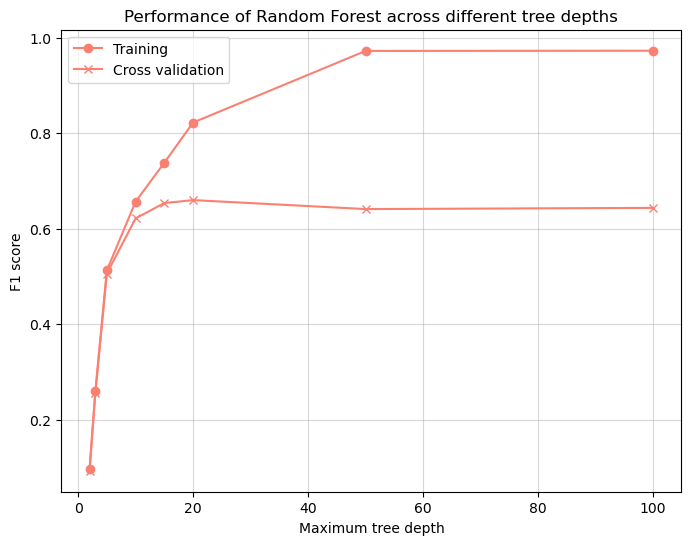

In [41]:
# plotting training and validation performance
plt.figure(figsize=(8,6))
#training plot
plt.plot(rf_results['param_rf__max_depth'],rf_results['mean_train_score'], marker='o',label="Training",color='salmon')
#validation plot
plt.plot(rf_results['param_rf__max_depth'],rf_results['mean_test_score'], marker='x',label='Cross validation',color='salmon')

plt.xlabel("Maximum tree depth")
plt.ylabel("F1 score")
plt.title("Performance of Random Forest across different tree depths")
plt.legend()
plt.grid(alpha=0.5)
plt.show()

**7. Model Evaluation**

The models were evaluated using accuracy, precision, recall, F1-score and ROC-AUC. Cross-validation was used to assess model performance during development, while the held-out test set was used for the final evaluation and comparison of the models.

In [42]:
# comparing evaluation metrics for the logistic regression models
models = {
    "Logistic Regression (no regularisation)" : logistic_pipeline,
    "L1 Logistic Regression" : best_l1,
    "L2 Logistic Regression" :best_l2, 
    "Random Forest": rf_optimal
}

results = []
for name, model in models.items():
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:,1]

    results.append({
       "Model": name,
       "Accuracy": accuracy_score(y_test,y_pred),
       "Precision": precision_score(y_test,y_pred, pos_label=pos),
       "Recall": recall_score(y_test, y_pred, pos_label=pos),
       "F1 Score": f1_score(y_test, y_pred, pos_label=pos),
       "AUC-ROC": roc_auc_score(y_test, y_prob)

})
results_df = pd.DataFrame(results)
results_df

,Model,Accuracy,Precision,Recall,F1 Score,AUC-ROC
0,Logistic Regression (no regularisation),0.857714,0.741717,0.628189,0.680249,0.911164
1,L1 Logistic Regression,0.857560,0.741522,0.627551,0.679793,0.911446
2,L2 Logistic Regression,0.857714,0.741717,0.628189,0.680249,0.911468
3,Random Forest,0.858943,0.758347,0.608418,0.675159,0.908804


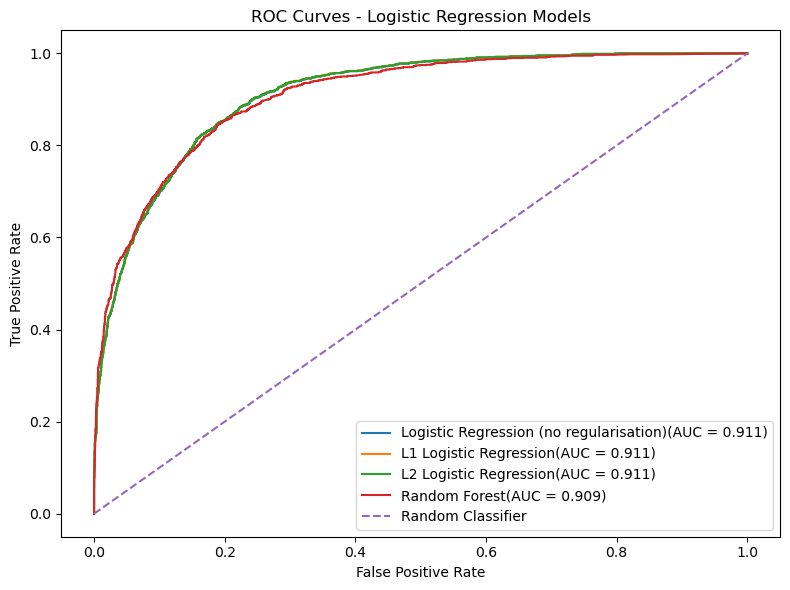

In [43]:
# comparing the roc-auc score of the logistic regression models

plt.figure(figsize=(8,6))

for name, model in models.items():
    y_prob = model.predict_proba(X_test)[:,1]
    y_pred = model.predict(X_test)

    fpr, tpr, thresholds = roc_curve(y_test, y_prob, pos_label=pos)
    auc = roc_auc_score((y_test == ' >50K').astype(int),y_prob)
    plt.plot(fpr, tpr, label=f'{name}(AUC = {auc:.3f})')

plt.plot([0,1],[0,1],linestyle='--',label = 'Random Classifier')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves - Logistic Regression Models")
plt.legend()
plt.tight_layout()
plt.show()

**8. Permutation Feature Importance**

Permutation Feature Importance (PFI) was used to identify the most influential predictors in the L2 logistic regression and random forest model. Feature importance was measured by examining the decrease in F1-score when individual features were randomly shuffled.

In [44]:
#computing feature importance for each model
from sklearn.inspection import permutation_importance

# permutation feature importance for logistic regression
pfi_l2 = permutation_importance(best_l2, X_test, y_test, n_repeats=5,scoring=f1_scorer, random_state=42)

# creating a dataframe for the results
pfi_l2_df = pd.DataFrame({
    'Feature': X_test.columns,
    'Importance_mean': pfi_l2.importances_mean,
    "Importance_std": pfi_l2.importances_std
}).sort_values(by = 'Importance_mean',ascending=False)

pfi_l2_df

,Feature,Importance_mean,Importance_std
5,marital-status,0.174131,0.002501
4,education-num,0.160394,0.007012
10,capital-gain,0.078694,0.004550
6,occupation,0.054706,0.005743
7,relationship,0.030401,0.004171
9,sex,0.028413,0.002708
12,hours-per-week,0.026986,0.004251
0,age,0.023277,0.003627
11,capital-loss,0.013166,0.001235
1,workclass,0.008957,0.001872


In [45]:

# permutation feature importance from random forest
pfi_rf = permutation_importance(rf_optimal, X_test, y_test, n_repeats=10,scoring=f1_scorer, random_state=42)

# creating a dataframe for the results
pfi_rf_df = pd.DataFrame({
    'Feature': X_test.columns,
    'Importance_mean': pfi_rf.importances_mean,
    "Importance_std": pfi_rf.importances_std
}).sort_values(by = 'Importance_mean',ascending=False)

pfi_rf_df

,Feature,Importance_mean,Importance_std
7,relationship,0.095705,0.007167
10,capital-gain,0.084181,0.004427
5,marital-status,0.068275,0.005873
4,education-num,0.048949,0.005283
6,occupation,0.038992,0.008261
9,sex,0.034325,0.005741
0,age,0.032623,0.006368
12,hours-per-week,0.021866,0.005154
11,capital-loss,0.011973,0.001315
3,education,0.005249,0.006078


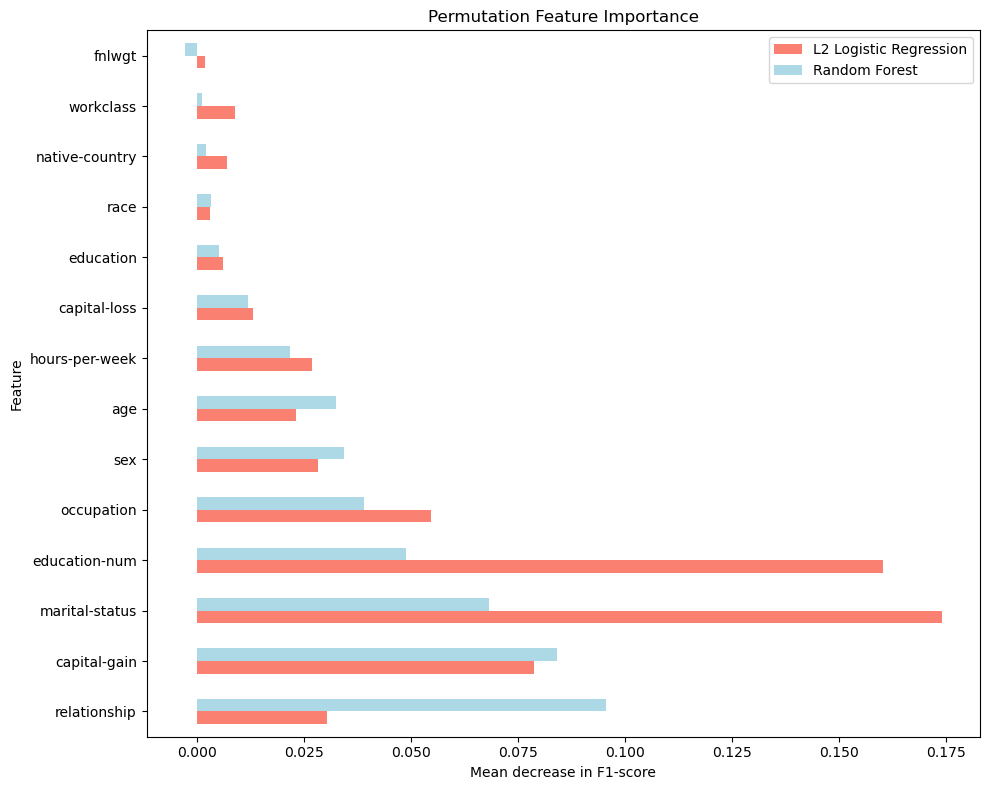

In [46]:
pfi_results = pd.DataFrame({
    'Feature': X_test.columns,
    'L2 Logistic Regression': pfi_l2.importances_mean,
    'Random Forest': pfi_rf.importances_mean
}).sort_values(by="Random Forest", ascending=False)

# plotting importance means across the models
pfi_results.set_index('Feature').plot(
    kind='barh',color=['salmon','lightblue'],
    figsize=(10, 8)
)
plt.xlabel('Mean decrease in F1-score')
plt.title('Permutation Feature Importance')
plt.tight_layout()
plt.show()

**9. Conclusion**

This project investigated the use of logistic regression and random forest for income classification. The analysis focused on how regularisation and model complexity influence predictive performance and generalisation. The results were used to compare the models and identify the most influential predictors.